# 07. Crime coefficients: MPS results first

This notebook reads the saved M1–M7 estimates from notebooks 02 (MPS) and 01 (supplied original data). **MPS is the main analysis here:** all crime, violence and property crime under current-year, previous-year and prior-12-month exposure. The supplied original data appear in a short comparison at the end.

M1 has no crime coefficient, so coefficient figures start at M2. The crime regressor is `ln(1 + crime count)` and the outcome is log sale price. A significance symbol tests one coefficient against zero; a change in symbols across models is not a test of the difference between coefficients. These are associations, not causal effects.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/02_crime_mps_outputs/combined_primary_models.csv').is_file()
             and (p / 'data/01_crime_original_outputs/combined_primary_models.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run notebooks 01 and 02 first to save the model CSVs.')
OUT = ROOT / 'data/07_crime_results_outputs'
OUT.mkdir(parents=True, exist_ok=True)
MODEL_ORDER = [f'M{i}' for i in range(2, 8)]
CRIME_ORDER = ['All crime', 'Violent crime', 'Property crime']
TIMINGS = ['Current year', 'Previous year', 'Prior 12 months']
SOURCE_PANELS = [
    ('MPS', 'Current year', '02_crime_mps_outputs', 'primary_annual'),
    ('MPS', 'Previous year', '02_crime_mps_outputs', 'primary_lagyear'),
    ('MPS', 'Prior 12 months', '02_crime_mps_outputs', 'primary_prior12'),
    ('Original/Stata', 'Current year', '01_crime_original_outputs', 'primary_annual'),
    ('Original/Stata', 'Previous year', '01_crime_original_outputs', 'primary_lagyear'),
]
CRIME_NAMES = {
    'allcrime': 'All crime', 'violent_crime': 'Violent crime', 'propertycrime': 'Property crime',
    'mps_all': 'All crime', 'mps_violence': 'Violent crime', 'mps_property': 'Property crime',
}

parts = []
for panel_id, (source, timing, folder, panel) in enumerate(SOURCE_PANELS):
    frame = pd.read_csv(ROOT / 'data' / folder / 'combined_primary_models.csv')
    part = frame.loc[frame.panel.eq(panel) & frame.model.isin(MODEL_ORDER)].copy()
    part['source'], part['timing'], part['panel_id'] = source, timing, panel_id
    part['crime_measure'] = part.crime.map(CRIME_NAMES)
    expected = pd.MultiIndex.from_product([MODEL_ORDER, CRIME_ORDER], names=['model', 'crime_measure'])
    actual = pd.MultiIndex.from_frame(part[['model', 'crime_measure']])
    if len(actual) != len(expected) or not actual.is_unique or not actual.difference(expected).empty or not expected.difference(actual).empty:
        raise ValueError(f'Incomplete or duplicate coefficient panel: {source}, {timing}')
    if part.N.nunique() != 1:
        raise ValueError(f'Sample size varies within {source}, {timing}')
    parts.append(part)
coefficients = pd.concat(parts, ignore_index=True)
fields = ['beta', 'se', 'p', 'ci_low', 'ci_high', 'N', 'clusters', 'crime_residual_sd']
if coefficients[fields].isna().any().any():
    raise ValueError('A coefficient, uncertainty, or residual-SD field is missing.')
coefficients['significance'] = np.select(
    [coefficients.p.lt(.001), coefficients.p.lt(.01), coefficients.p.lt(.05)],
    ['***', '**', '*'], default='ns')
coefficients['significant_5pct'] = coefficients.p.lt(.05)
coefficients = coefficients.sort_values(['panel_id', 'crime_measure', 'model']).reset_index(drop=True)
export_columns = ['source', 'timing', 'crime_measure', 'model', 'beta', 'se', 'p', 'ci_low', 'ci_high',
                  'crime_residual_sd', 'significance', 'significant_5pct', 'N', 'clusters',
                  'panel', 'crime', 'crime_exposure', 'fixed_effects']
export = coefficients[export_columns].rename(columns={
    'p': 'p_value', 'N': 'n_sales', 'clusters': 'n_lsoa_clusters'})
export.to_csv(OUT / 'crime_coefficients_m2_m7.csv', index=False, float_format='%.16g')
mps = coefficients.loc[coefficients.source.eq('MPS')].copy()
original_data = coefficients.loc[coefficients.source.eq('Original/Stata')].copy()
display(pd.DataFrame([{'Source': source, 'Timing': timing, 'Sales': int(part.N.iloc[0])}
                      for (source, timing, *_), part in zip(SOURCE_PANELS, parts)]))
print(f'Saved {len(export)} estimates: {OUT / "crime_coefficients_m2_m7.csv"}')

,Source,Timing,Sales
0,MPS,Current year,338347
1,MPS,Previous year,338347
2,MPS,Prior 12 months,338347
3,Original/Stata,Current year,453740
4,Original/Stata,Previous year,453740


Saved 90 estimates: /home/rachmiel/he3027/data/07_crime_results_outputs/crime_coefficients_m2_m7.csv


## MPS coefficient and significance heatmap

Rows are crime categories; columns are M2–M7. Color shows the signed coefficient, and each cell prints its value and significance (`***` p < .001, `**` p < .01, `*` p < .05, `ns` otherwise). All three timing panels use the same MPS color scale. Read the number as well as the color: the scale spans every MPS estimate, so small M7 estimates can look similar.

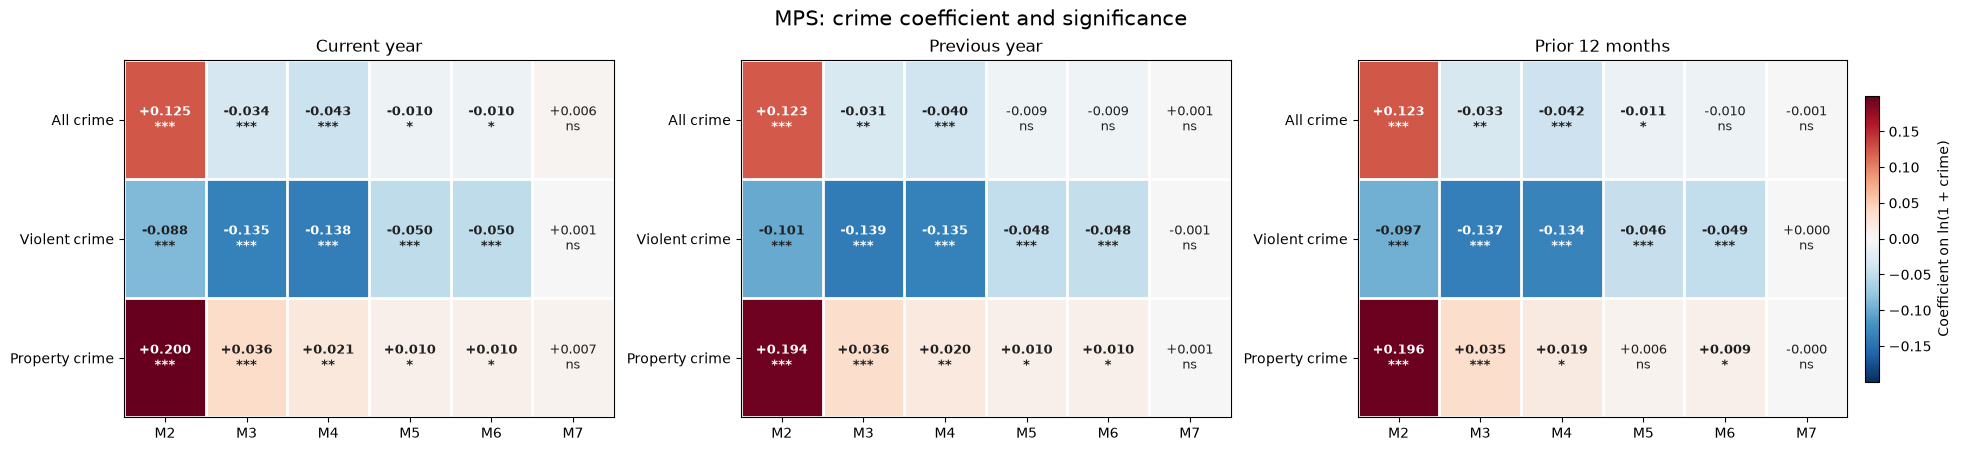

In [2]:
def coefficient_heatmap(data, source, timings, filename):
    subset = data.loc[data.source.eq(source)]
    limit = max(float(subset.beta.abs().max()), 1e-12)
    norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
    fig, axes = plt.subplots(1, len(timings), figsize=(6.5 * len(timings), 4.4), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, timing in zip(axes, timings):
        panel = subset.loc[subset.timing.eq(timing)]
        values = panel.pivot(index='crime_measure', columns='model', values='beta').reindex(index=CRIME_ORDER, columns=MODEL_ORDER)
        symbols = panel.pivot(index='crime_measure', columns='model', values='significance').reindex(index=CRIME_ORDER, columns=MODEL_ORDER)
        image = ax.imshow(values.to_numpy(), cmap='RdBu_r', norm=norm, aspect='auto')
        ax.set_xticks(range(len(MODEL_ORDER)), MODEL_ORDER)
        ax.set_yticks(range(len(CRIME_ORDER)), CRIME_ORDER)
        ax.set_title(timing)
        for i in range(len(CRIME_ORDER)):
            for j in range(len(MODEL_ORDER)):
                value, symbol = values.iloc[i,j], symbols.iloc[i,j]
                ink = 'white' if abs(value) > .55 * limit else '#202020'
                ax.text(j, i, f'{value:+.3f}\n{symbol}', ha='center', va='center',
                        color=ink, fontsize=9, fontweight='bold' if symbol != 'ns' else 'normal')
        ax.set_xticks(np.arange(-.5, len(MODEL_ORDER), 1), minor=True)
        ax.set_yticks(np.arange(-.5, len(CRIME_ORDER), 1), minor=True)
        ax.grid(which='minor', color='white', linewidth=2)
        ax.tick_params(which='minor', bottom=False, left=False)
    fig.suptitle(f'{source}: crime coefficient and significance', fontsize=15)
    fig.colorbar(image, ax=axes, shrink=.8, pad=.01, label='Coefficient on ln(1 + crime)')
    fig.savefig(OUT / filename, dpi=180, bbox_inches='tight')
    plt.show()

coefficient_heatmap(coefficients, 'MPS', TIMINGS, 'mps_coefficients_significance.png')

## MPS: focus on the M6-to-M7 change

M6 includes MSOA and year-quarter fixed effects; M7 uses LSOA and year-quarter fixed effects. The figure shows each estimate with its 95% confidence interval. The table also reports the LSOA-clustered standard error and the SD of `ln(1 + crime)` after **area and time fixed effects only**. That SD has not additionally removed the other controls. A lower SD does not by itself establish why a coefficient changed.

,timing,crime_measure,model,N,beta,se,p,ci_low,ci_high,crime_residual_sd,significance
4,Current year,All crime,M6,338347,-0.01026,0.00502,0.04106,-0.02011,-0.00042,0.4482,*
5,Current year,All crime,M7,338347,0.00572,0.00519,0.27051,-0.00446,0.01590,0.1307,ns
22,Previous year,All crime,M6,338347,-0.00880,0.00507,0.08250,-0.01874,0.00113,0.4467,ns
23,Previous year,All crime,M7,338347,0.00077,0.00566,0.89233,-0.01034,0.01187,0.1288,ns
40,Prior 12 months,All crime,M6,338347,-0.00967,0.00506,0.05621,-0.01960,0.00026,0.4471,ns
41,Prior 12 months,All crime,M7,338347,-0.00059,0.00605,0.92291,-0.01246,0.01128,0.1299,ns
10,Current year,Property crime,M6,338347,0.00983,0.00474,0.03834,0.00053,0.01913,0.4651,*
11,Current year,Property crime,M7,338347,0.00739,0.00438,0.09140,-0.00119,0.01597,0.1571,ns
28,Previous year,Property crime,M6,338347,0.00996,0.00483,0.03915,0.00050,0.01943,0.4612,*
29,Previous year,Property crime,M7,338347,0.00060,0.00443,0.89153,-0.00809,0.00929,0.1538,ns


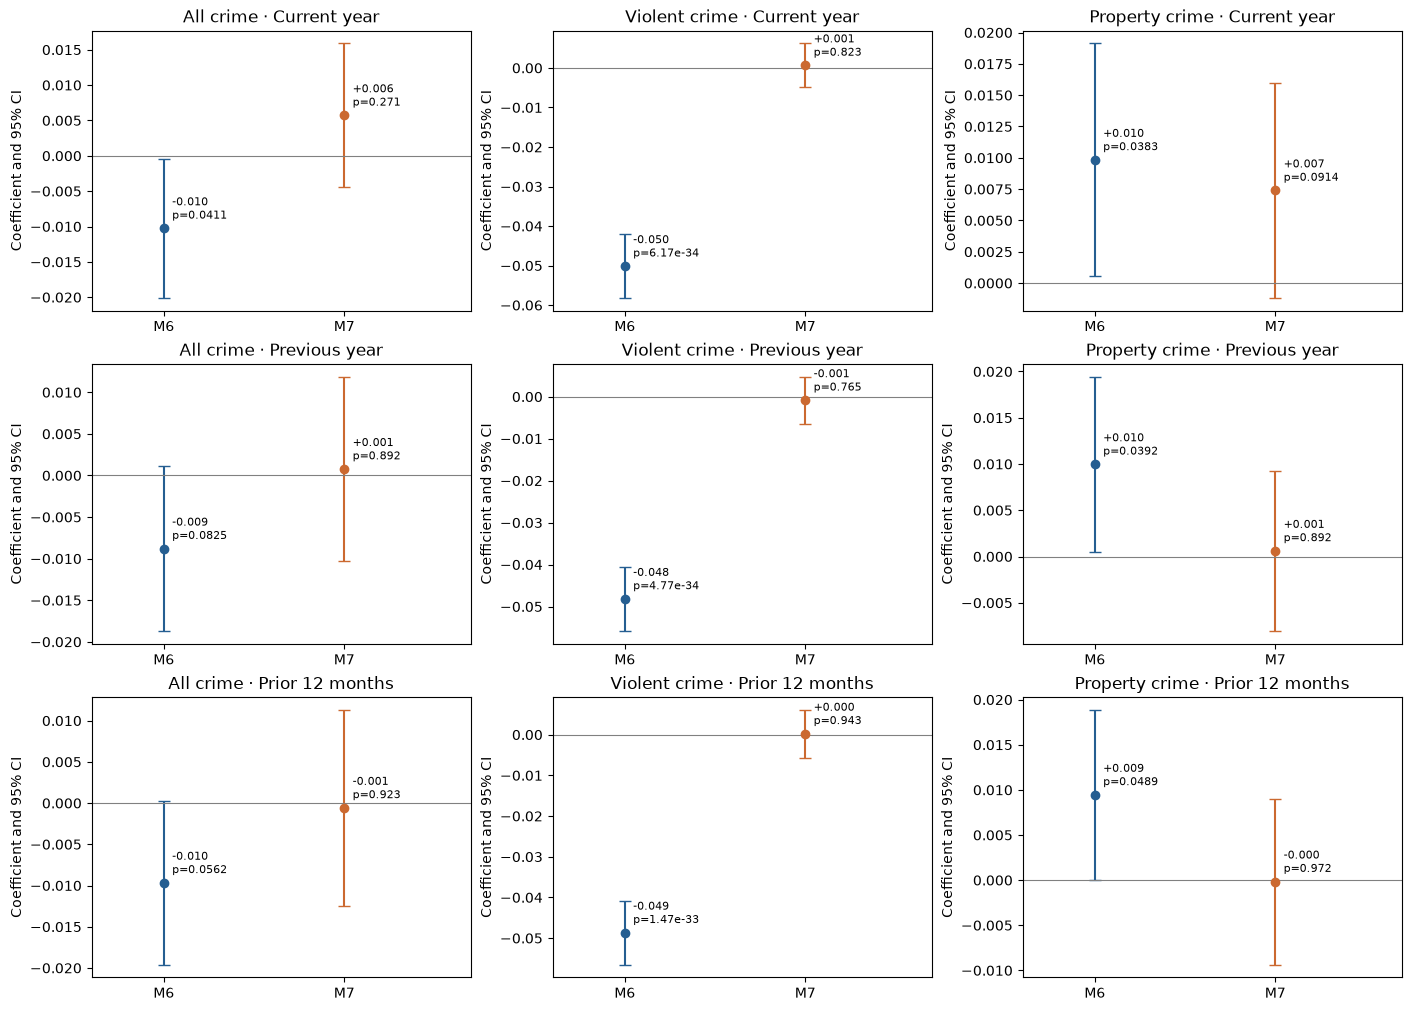

MPS at 5%: M6 significant in 7/9, M7 significant in 0/9 crime × timing estimates.


In [3]:
focus = mps.loc[mps.model.isin(['M6','M7']),
                ['timing','crime_measure','model','N','beta','se','p','ci_low','ci_high','crime_residual_sd','significance']].copy()
focus = focus.sort_values(['crime_measure','timing','model'])
focus.to_csv(OUT / 'mps_m6_m7_focus.csv', index=False, float_format='%.16g')
display(focus.round({'beta':5,'se':5,'p':5,'ci_low':5,'ci_high':5,'crime_residual_sd':4}))

fig, axes = plt.subplots(3, 3, figsize=(14, 10), constrained_layout=True)
for i, timing in enumerate(TIMINGS):
    for j, crime in enumerate(CRIME_ORDER):
        ax = axes[i,j]
        panel = focus.loc[focus.timing.eq(timing) & focus.crime_measure.eq(crime)].set_index('model').reindex(['M6','M7'])
        for k, model in enumerate(['M6','M7']):
            row = panel.loc[model]
            ax.errorbar(k, row.beta, yerr=[[row.beta-row.ci_low],[row.ci_high-row.beta]],
                        fmt='o', capsize=4, color='#255e91' if model=='M6' else '#cb6930')
            ax.annotate(f'{row.beta:+.3f}\np={row.p:.3g}', (k, row.beta), xytext=(6,7),
                        textcoords='offset points', fontsize=8)
        ax.axhline(0, color='0.5', linewidth=.8)
        ax.set_xticks([0,1], ['M6','M7'])
        ax.set_xlim(-.4,1.7)
        ax.set_title(f'{crime} · {timing}')
        ax.set_ylabel('Coefficient and 95% CI')
fig.savefig(OUT / 'mps_m6_m7_precision.png', dpi=180, bbox_inches='tight')
plt.show()

m7_count = int(mps.loc[mps.model.eq('M7'), 'significant_5pct'].sum())
m6_count = int(mps.loc[mps.model.eq('M6'), 'significant_5pct'].sum())
print(f'MPS at 5%: M6 significant in {m6_count}/9, M7 significant in {m7_count}/9 crime × timing estimates.')

## MPS coefficient movement from M2

Each cell is `β(Mj) − β(M2)` for that crime category and timing. M2 is zero by construction in this figure. A positive cell can mean a negative coefficient moved toward zero. These differences have no uncertainty interval in the saved outputs, so the figure is descriptive.

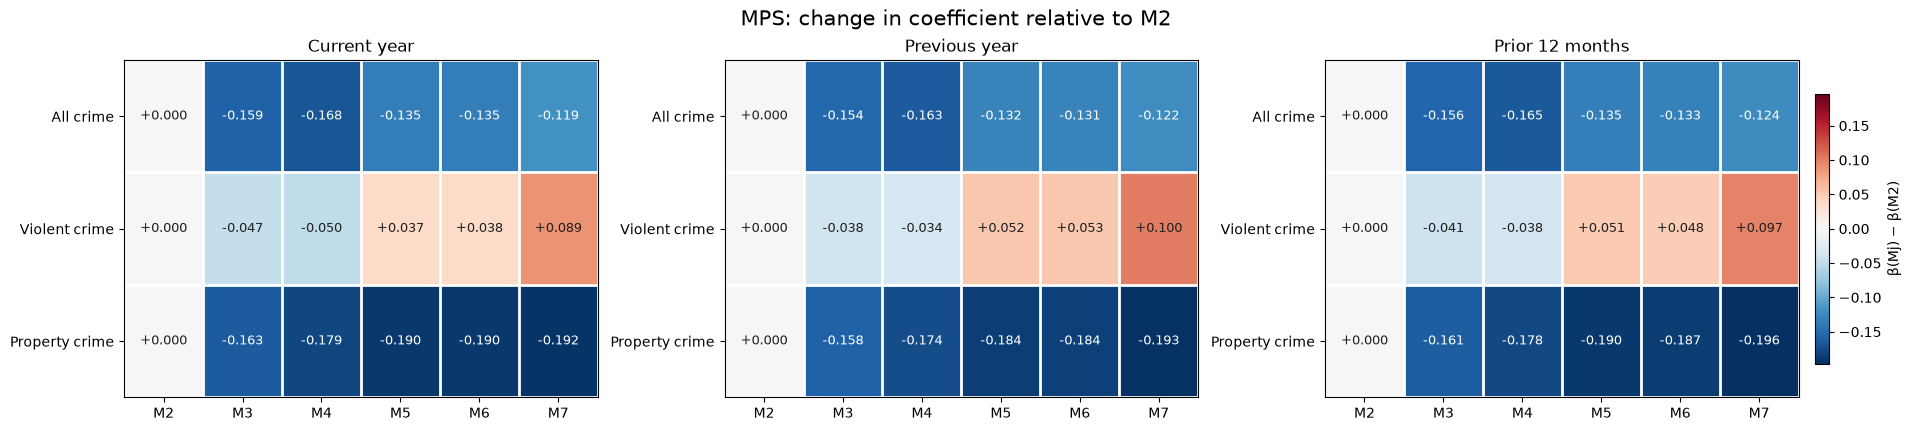

In [4]:
change_rows = []
for timing in TIMINGS:
    panel = mps.loc[mps.timing.eq(timing)]
    for crime in CRIME_ORDER:
        b = panel.loc[panel.crime_measure.eq(crime)].set_index('model').reindex(MODEL_ORDER).beta
        for model in MODEL_ORDER:
            change_rows.append({'timing':timing,'crime_measure':crime,'model':model,'beta':b[model],
                                'change_from_m2':b[model]-b['M2']})
changes = pd.DataFrame(change_rows)
changes.to_csv(OUT / 'mps_change_from_m2.csv', index=False, float_format='%.16g')
limit = max(float(changes.change_from_m2.abs().max()), 1e-12)
fig, axes = plt.subplots(1, 3, figsize=(19,4.2), constrained_layout=True)
for ax, timing in zip(axes, TIMINGS):
    panel = changes.loc[changes.timing.eq(timing)]
    matrix = panel.pivot(index='crime_measure',columns='model',values='change_from_m2').reindex(index=CRIME_ORDER,columns=MODEL_ORDER)
    image = ax.imshow(matrix.to_numpy(),cmap='RdBu_r',norm=TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit),aspect='auto')
    ax.set_xticks(range(len(MODEL_ORDER)),MODEL_ORDER)
    ax.set_yticks(range(len(CRIME_ORDER)),CRIME_ORDER)
    ax.set_title(timing)
    for i in range(len(CRIME_ORDER)):
        for j in range(len(MODEL_ORDER)):
            value = matrix.iloc[i,j]
            ax.text(j,i,f'{value:+.3f}',ha='center',va='center',fontsize=9,
                    color='white' if abs(value)>.55*limit else '#202020')
    ax.set_xticks(np.arange(-.5,len(MODEL_ORDER),1),minor=True)
    ax.set_yticks(np.arange(-.5,len(CRIME_ORDER),1),minor=True)
    ax.grid(which='minor',color='white',linewidth=2)
    ax.tick_params(which='minor',bottom=False,left=False)
fig.suptitle('MPS: change in coefficient relative to M2',fontsize=15)
fig.colorbar(image,ax=axes,shrink=.8,pad=.01,label='β(Mj) − β(M2)')
fig.savefig(OUT / 'mps_change_from_m2.png',dpi=180,bbox_inches='tight')
plt.show()

## Reading the MPS results

All nine MPS M7 estimates are insignificant at the 5% threshold. Some M6 estimates were **already** insignificant, so “significant through M6” is not universal. The M6-to-M7 change often involves a smaller point estimate as well as less fixed-effect-residualized crime variation. M7 removes stable LSOA differences while retaining crime changes within LSOAs over time. A near-zero M7 estimate does not show that the true causal effect is zero: crime measurement, lag choice, time-varying local conditions and spatial spillovers remain relevant.

The original-data panels below are a source comparison. Their crime definitions and sales samples differ from MPS, so differences between the two sources should not be interpreted as a direct test of one dataset's accuracy.

## Supplied original data: comparison only

The supplied series has current-year and previous-year exposures. Its violent-crime count is zero throughout 2014–2015, and its 2015 property and all-crime endpoints are anomalously low in the project audit. The original current-year violence and previous-year property M7 estimates remain significant in the full sample. The endpoint-year robustness notebook (08) examines their stability separately.

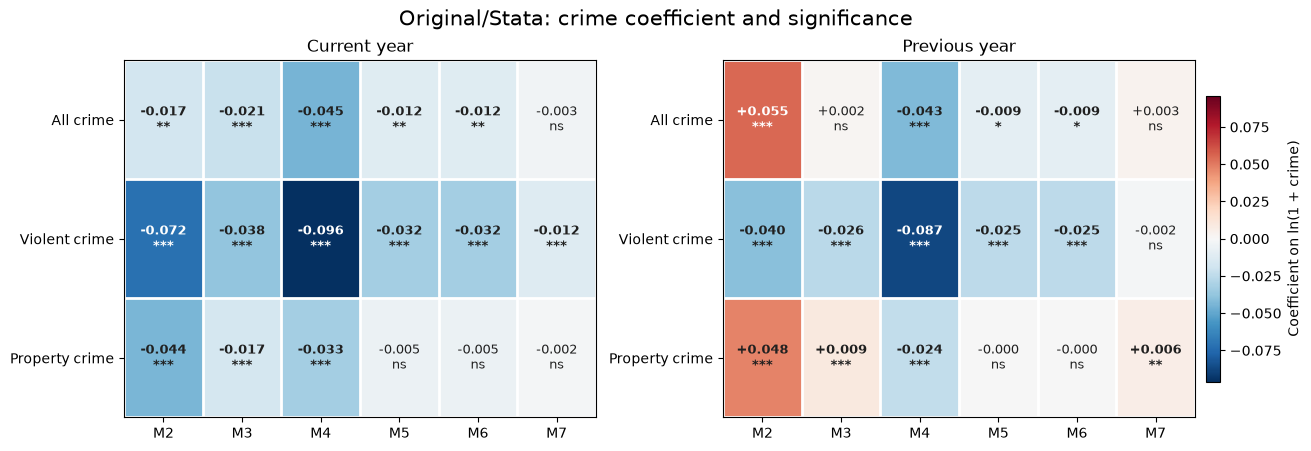

,source,timing,crime_measure,model,N,beta,se,p,ci_low,ci_high,significance
58,Original/Stata,Current year,All crime,M6,453740,-0.01172,0.00400,0.00343,-0.01957,-0.00387,**
59,Original/Stata,Current year,All crime,M7,453740,-0.00327,0.00383,0.39314,-0.01078,0.00424,ns
64,Original/Stata,Current year,Property crime,M6,453740,-0.00526,0.00404,0.19289,-0.01317,0.00266,ns
65,Original/Stata,Current year,Property crime,M7,453740,-0.00183,0.00242,0.45121,-0.00657,0.00292,ns
70,Original/Stata,Current year,Violent crime,M6,453740,-0.03227,0.00284,0.00000,-0.03784,-0.02671,***
71,Original/Stata,Current year,Violent crime,M7,453740,-0.01206,0.00187,0.00000,-0.01574,-0.00839,***
76,Original/Stata,Previous year,All crime,M6,453740,-0.00914,0.00388,0.01861,-0.01676,-0.00153,*
77,Original/Stata,Previous year,All crime,M7,453740,0.00341,0.00348,0.32651,-0.00340,0.01022,ns
82,Original/Stata,Previous year,Property crime,M6,453740,-0.00012,0.00361,0.97457,-0.00720,0.00697,ns
83,Original/Stata,Previous year,Property crime,M7,453740,0.00642,0.00223,0.00410,0.00204,0.01080,**


Optional original-source sensitivity from notebook 08:


,sample_label,timing,crime,N,beta,se,p,significance
16,Full: 2011–2015,Current year,violent_crime,453740,-0.01206,0.00187,0.00000,***
35,Full: 2011–2015,Previous year,propertycrime,453740,0.00642,0.00223,0.00410,**
52,Restricted: 2012–2014,Current year,violent_crime,316091,-0.00731,0.00228,0.00139,**
71,Restricted: 2012–2014,Previous year,propertycrime,316091,0.00395,0.00334,0.23646,ns
88,Pre-2014: 2012–2013,Current year,violent_crime,198948,-0.00517,0.00399,0.19484,ns
107,Pre-2014: 2012–2013,Previous year,propertycrime,198948,0.00441,0.00435,0.31043,ns


In [5]:
coefficient_heatmap(coefficients, 'Original/Stata', TIMINGS[:2], 'original_coefficients_significance.png')
comparison = coefficients.loc[coefficients.model.isin(['M6','M7']),
                              ['source','timing','crime_measure','model','N','beta','se','p','ci_low','ci_high','significance']].copy()
comparison.to_csv(OUT / 'source_m6_m7_comparison.csv', index=False, float_format='%.16g')
display(comparison.loc[comparison.source.eq('Original/Stata')].round({'beta':5,'se':5,'p':5,'ci_low':5,'ci_high':5}))

robustness_path = ROOT / 'data/08_crime_original_robustness_outputs/three_samples_m2_m7_significance.csv'
if robustness_path.is_file():
    sensitivity = pd.read_csv(robustness_path)
    selected = sensitivity.loc[sensitivity.model.eq('M7') & (
        (sensitivity.crime.eq('propertycrime') & sensitivity.timing.eq('Previous year')) |
        (sensitivity.crime.eq('violent_crime') & sensitivity.timing.eq('Current year'))),
        ['sample_label','timing','crime','N','beta','se','p','significance']]
    print('Optional original-source sensitivity from notebook 08:')
    display(selected.round({'beta':5,'se':5,'p':5}))

**Files:** `crime_coefficients_m2_m7.csv` contains all 90 M2–M7 estimates and significance fields. `mps_m6_m7_focus.csv` and the MPS figures support the main interpretation. This notebook does not update the dashboard.